# 05 | Submissão FInal | Score, Monitoramento Sem Target e Submissão Kaggle

Este caderno executa o **pipeline de produção e entrega final** sobre a base cega do Kaggle (`test_transaction.csv` e `test_identity.csv`), utilizando o artefato congelado exportado em `02_Modelagem.ipynb` (**`LGBM_Otimizado` · 30 features · Calibração Isotônica · Threshold Dinâmico por Ticket**).


## Sumário

| Seção | Etapa de MLOps | Entregáveis e Verificações |
|:---:|---|---|
| [**1.0**](#10-preparacao-do-ambiente-download-e-carga) | Preparação e Carga | Carga do artefato final (`30` features), `df_master` e download/leitura do `Test` via `kagglehub` |
| [**2.0**](#20-engenharia-de-atributos-paridade-e-sanidade-de-entrada) | Paridade de Pipeline | Normalização `id-` → `id_`, alinhamento `log1p` com `df_master`, `*_freq` do Treino e auditoria de `OOV (-1)` |
| [**3.0**](#30-gate-de-estabilidade-das-features-in-time-vs-test) | Feature Drift | PSI e KS das `30` features (`In-Time × Test`) cruzados com a importância no modelo (`Risco_Drift`) |
| [**4.0**](#40-escoragem-calibracao-isotonica-e-sanidade-dos-scores) | Inferência e Score Drift | Comparativo `Validação × OOT × Test` (`prob_cal`, quantis, `% bloqueio`, `% GMV retido`) e PSI do Score |
| [**5.0**](#50-monitoramento-temporal-de-acionamento-evolucao-semanal) | Estabilidade Temporal | Evolução semanal da taxa de bloqueio e `prob_cal` no `Test` frente ao baseline `OOT` |
| [**6.0**](#60-exportacao-das-submissoes-e-sintese-executiva) | Entrega e Consolidação | `submission_kaggle.csv`, `predicoes_test_binarias.csv` e `test_resumo_escoragem.json` |

## 1.0 Preparação do Ambiente, Download e Carga

Configuramos os diretórios do projeto, carregamos o artefato congelado (`artifacts/modelo_fraude_final.joblib`) e a base de referência (`df_master.parquet`), e garantimos que `test_transaction.csv` e `test_identity.csv` estejam disponíveis em `data/raw/`.

In [2]:
# ==============================================================================
# 1.1 CONFIGURAÇÃO DO AMBIENTE, DIRETÓRIOS E CARGA DO ARTEFATO
# ==============================================================================
import gc
import os
import sys
import json
import warnings
import importlib
from pathlib import Path

warnings.filterwarnings('ignore')

# Resolução robusta da raiz do projeto (Local e Colab)
current_dir = Path(os.getcwd()).resolve()
if (current_dir / 'src').is_dir():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / 'src').is_dir():
    PROJECT_ROOT = current_dir.parent
elif (current_dir.parent.parent / 'src').is_dir():
    PROJECT_ROOT = current_dir.parent.parent
else:
    PROJECT_ROOT = current_dir

os.chdir(PROJECT_ROOT)
for p in [str(PROJECT_ROOT), os.path.abspath('.'), os.path.abspath('..')]:
    if p not in sys.path:
        sys.path.append(p)

import joblib
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Funções do projeto: módulos de src/ (antes centralizados em utils.py)
from src.visualization.theme import (
    aplicar_estilo_azul,
)
from src.features.engineering import (
    preparar_dados_teste_inferencia,
)
from src.models.artifacts import (
    aplicar_regra_dinamica,
)
from src.evaluation.metrics import (
    escorar_particao,
    comparar_escoragem_particoes,
    adicionar_bloco_temporal,
    resumir_predicoes_test,
)
from src.evaluation.drift import (
    relatorio_psi_vs_importancia_modelo,
    calcular_psi_scores,
)
from src.visualization.eval_plots import (
    plot_evolucao_predicoes_test,
    plot_psi_score_faixas,
    plot_comparativo_psi_features,
)

aplicar_estilo_azul()

# Diretórios oficiais
DIR_RAW  = PROJECT_ROOT / 'data' / 'raw'
DIR_PROC = PROJECT_ROOT / 'data' / 'processed'
DIR_SUB  = PROJECT_ROOT / 'data' / 'submissions'
DIR_ART  = PROJECT_ROOT / 'artifacts'
DIR_FIG  = PROJECT_ROOT / 'reports' / 'figures'
DIR_MET  = PROJECT_ROOT / 'reports' / 'metrics'
for d in [DIR_RAW, DIR_SUB, DIR_FIG, DIR_MET]:
    d.mkdir(parents=True, exist_ok=True)

# Carga do artefato congelado e metadados de treino
artefato = joblib.load(DIR_ART / 'modelo_fraude_final.joblib')
FEATURES = list(artefato['features'])
regra_decisao = artefato['regra_decisao']

meta_path = DIR_PROC / 'features_metadata.json'
meta = json.loads(meta_path.read_text(encoding='utf-8')) if meta_path.exists() else None
df_master = pd.read_parquet(DIR_PROC / 'df_master.parquet')

print(f"Projeto          : {PROJECT_ROOT}")
print(f"Modelo congelado : {artefato.get('nome_modelo', 'LGBM_Otimizado')} | {len(FEATURES)} features")
print(f"Regra dinâmica   : t_min={regra_decisao['t_min']:.4f}, t_max={regra_decisao['t_max']:.4f}, k={regra_decisao['k']:.5f}")
print(f"df_master (ref.) : {df_master.shape[0]:,} linhas × {df_master.shape[1]} colunas")

Projeto          : /content
Modelo congelado : LGBM_Otimizado | 30 features
Regra dinâmica   : t_min=0.0258, t_max=0.0513, k=0.00492
df_master (ref.) : 590,540 linhas × 152 colunas


In [3]:
# ==============================================================================
# 1.2 DOWNLOAD (KAGGLEHUB) E LEITURA DAS BASES DE TEST
# ==============================================================================
FORCAR_DOWNLOAD = False  # Altere para True se desejar baixar novamente mesmo com cache local
arq_test_tr = DIR_RAW / 'test_transaction.csv'
arq_test_id = DIR_RAW / 'test_identity.csv'
arq_sample_sub = DIR_RAW / 'sample_submission.csv'

if FORCAR_DOWNLOAD or not (arq_test_tr.exists() and arq_test_id.exists()):
    print("[KaggleHub] Autenticando e baixando arquivos da competição ieee-fraud-detection...")
    kagglehub.login()
    path_kaggle = kagglehub.competition_download(
        'ieee-fraud-detection',
        force_download=FORCAR_DOWNLOAD,
        output_dir=str(DIR_RAW),
    )
    print(f"Arquivos baixados em: {path_kaggle}")
else:
    print(f"[Cache local] Bases de teste encontradas em {DIR_RAW}.")

df_test_tr = pd.read_csv(arq_test_tr)
df_test_id = pd.read_csv(arq_test_id)

cols_hifen = [c for c in df_test_id.columns if c.startswith('id-')]
print(f"test_transaction : {df_test_tr.shape[0]:,} linhas × {df_test_tr.shape[1]} colunas | "
      f"TransactionID {df_test_tr['TransactionID'].min():,} → {df_test_tr['TransactionID'].max():,}")
print(f"test_identity    : {df_test_id.shape[0]:,} linhas × {df_test_id.shape[1]} colunas | "
      f"{len(cols_hifen)} colunas com hífen ('id-*') detectadas para normalização")

[Cache local] Bases de teste encontradas em /content/data/raw.
test_transaction : 506,691 linhas × 393 colunas | TransactionID 3,663,549 → 4,170,239
test_identity    : 141,907 linhas × 41 colunas | 38 colunas com hífen ('id-*') detectadas para normalização


## 2.0 Engenharia de Atributos, Paridade e Sanidade de Entrada

Garantimos paridade estrita entre o `Test` e a esteira de treinamento (`01_EDA.ipynb` + `02_Modelagem.ipynb`):
1. **Normalização de nomenclatura (`id-01` → `id_01`)** em `test_identity.csv`.
2. **Alinhamento de escala `log1p`:** igualamos a precisão `float32` na detecção de variáveis transformadas por `np.log1p` (evitando falsos desvios em contagens discretas como `vel_C2`). As `freq_*` globais foram removidas do `df_master` na EDA (leakage temporal); as frequências usadas pelo modelo (`card1_freq`, `card2_freq`, `addr1_freq`, `P_emaildomain_freq`) vêm **apenas dos 60% de Treino**, e categorias inéditas no `Test` recebem frequência `0`.
3. **Encoders e estatísticas pós-split ajustados apenas nos 60% de Treino**, auditando a taxa de categorias desconhecidas (`OOV = -1`) no `Test`.

In [4]:
# ==============================================================================
# 2.1 ENGENHARIA DE ATRIBUTOS, ALINHAMENTO LOG1P E AUDITORIA DE CATEGORIAS OOV
# ==============================================================================
prep_test = preparar_dados_teste_inferencia(
    df_test_tr=df_test_tr,
    df_test_id=df_test_id,
    df_master=df_master,
    features_modelo=FEATURES,
    meta=meta,
    train_ratio=0.60,
    test_ratio=0.20,
)

X_test = prep_test['X_test']
amt_usd_test = prep_test['amt_usd']
df_oov = prep_test['df_oov']

# Libera tabelas brutas e df_master após extração das matrizes enxutas
del df_test_tr, df_test_id, df_master
gc.collect()

# Asserções de integridade pré-escoragem
assert list(X_test.columns) == FEATURES, "Ordem/conjunto de colunas de X_test difere do artefato."
assert not np.isnan(prep_test['TransactionID']).any(), "TransactionID contém valores nulos."
assert np.isfinite(amt_usd_test).all(), "amt_usd contém NaN ou infinito."

print(f"Colunas convertidas p/ log1p : {len(prep_test['cols_log1p'])} | Ex.: {prep_test['cols_log1p'][:10]}")
print(f"Período Test (dias)          : {prep_test['TransactionDT'].min()/86400:.1f} → {prep_test['TransactionDT'].max()/86400:.1f}")

if not df_oov.empty:
    df_oov_mod = df_oov[df_oov['No_Modelo_Final']].reset_index(drop=True)
    display(
        df_oov_mod.style.format({
            'OOV_Val_%': '{:.2f}%', 'OOV_OOT_%': '{:.2f}%',
            'OOV_Test_Qtd': '{:,.0f}', 'OOV_Test_%': '{:.2f}%',
        }).set_caption('Auditoria de Categorias Inéditas (OOV = -1 no OrdinalEncoder) — Features do Modelo Final')
    )

Downcast concluído: 1567.1 MB -> 822.0 MB (-47.5%)
Downcast concluído: 53.3 MB -> 34.8 MB (-34.8%)
-----------------------------------------------------------------
X_train shape (60%): (354324, 150) | Taxa de Fraude: 3.38%
X_test  shape (20%): (118108, 150)  | Taxa de Fraude: 3.90%
X_oot   shape (20%): (118108, 150)  | Taxa de Fraude: 3.44%  [BLINDADO P/ AVALIAÇÃO FINAL]
Total de features preditoras: 150
Features lineares (LR): 46
Taxa de desbalanceamento (Treino): 28.56:1
Blocos mensais no Treino (GroupKFold): [0, 1, 2, 3] (Total: 4 meses)
-----------------------------------------------------------------
[Teste] Matriz pronta: 506,691 linhas × 30 features | 67 colunas em escala log1p.
Colunas convertidas p/ log1p : 67 | Ex.: ['TransactionAmt', 'card3', 'dist1', 'dist2', 'vel_C2', 'vel_C5', 'vel_C8', 'vel_C12', 'delta_D1', 'delta_D2']
Período Test (dias)          : 213.0 → 396.0


,Feature,No_Modelo_Final,Categorias_Treino,OOV_Val_%,OOV_OOT_%,OOV_Test_Qtd,OOV_Test_%
0,P_emaildomain,True,60,0.00%,0.00%,2,0.00%
1,ProductCD,True,5,0.00%,0.00%,0,0.00%
2,match_M4_cat,True,4,0.00%,0.00%,0,0.00%
3,cartao_tipo_cat,True,3,0.00%,0.00%,0,0.00%


## 3.0 Gate de Estabilidade das Features (`In-Time` vs. `Test`)

Antes de avaliar os escores, inspecionamos o **Population Stability Index (PSI)** e o deslocamento **KS** das **`30` features** do modelo entre a janela **In-Time (`Treino + Validação`)** e o **`Test`**, ponderando cada variável pela sua participação nos splits do `LGBM_Otimizado` (`Risco_Drift = PSI × %_Importancia`).

* **Estável:** `PSI < 0,10` · **Alerta:** `0,10 ≤ PSI < 0,25` · **Crítico:** `PSI ≥ 0,25`.

Status das 30 features do modelo (In-Time → Test): {'Estável': 30, 'Alerta': 0, 'Crítico': 0}


,Feature,Status,PSI,KS_shift,Splits_Modelo,%_Importancia,Risco_Drift,%_Nulos_InTime,%_Nulos_Test
0,delta_D15,Estável,0.0968,0.1383,614,5.80%,0.0056,16.5%,2.4%
1,match_cont_F,Estável,0.0574,0.1026,133,1.26%,0.0007,0.0%,0.0%
2,dist1,Estável,0.0426,0.0651,387,3.66%,0.0016,60.8%,57.5%
3,delta_D10,Estável,0.0371,0.0931,546,5.16%,0.0019,14.1%,2.5%
4,vel_C2,Estável,0.0223,0.0231,462,4.36%,0.0010,0.0%,0.0%
5,delta_D8,Estável,0.0184,0.0365,344,3.25%,0.0006,87.0%,85.3%
6,V164,Estável,0.0157,0.0669,176,1.66%,0.0003,85.2%,85.0%
7,delta_D2,Estável,0.0152,0.0661,732,6.91%,0.0010,49.0%,46.3%
8,card1_freq,Estável,0.0107,0.0304,"1,010",9.54%,0.0010,0.0%,0.0%
9,V70,Estável,0.0100,0.0477,148,1.40%,0.0001,14.2%,2.5%


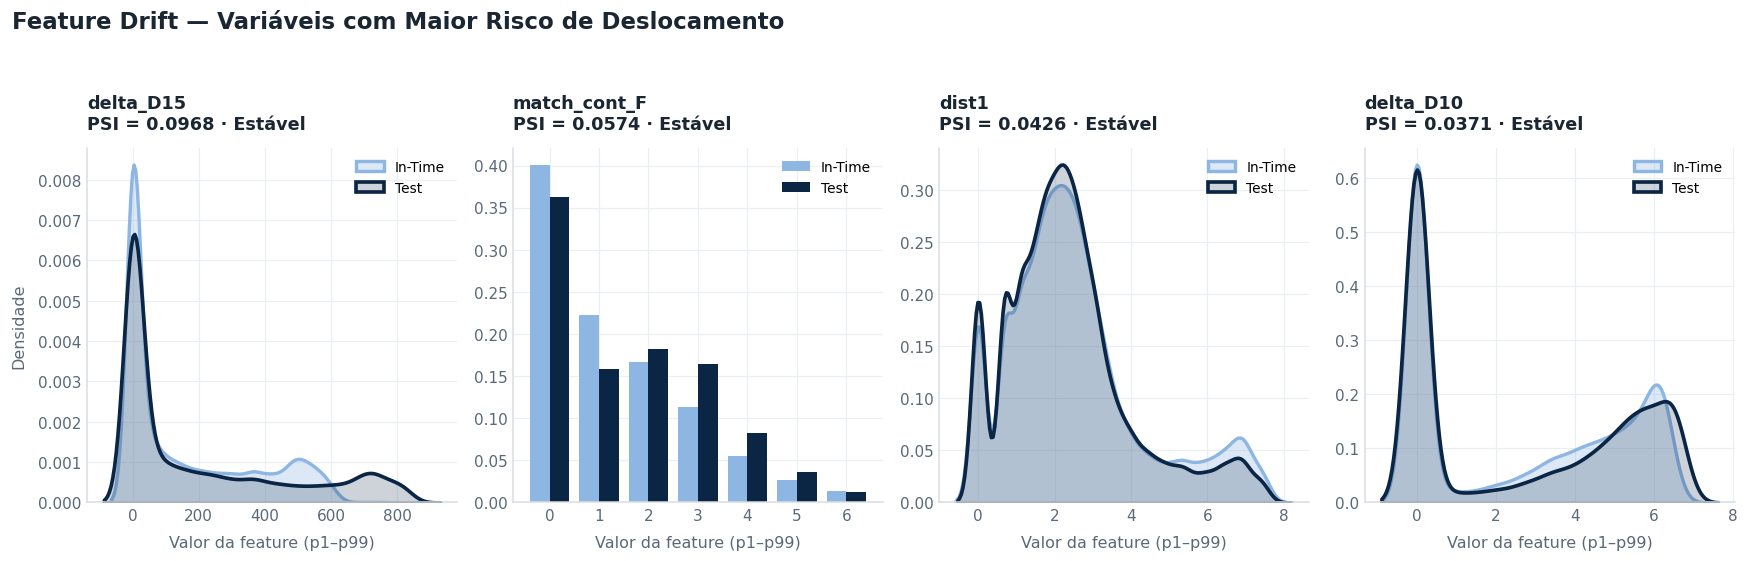

In [5]:
# ==============================================================================
# 3.1 PSI DAS 30 FEATURES DO MODELO CRUZADO COM IMPORTÂNCIA (IN-TIME VS. TEST)
# ==============================================================================
df_psi_feats = relatorio_psi_vs_importancia_modelo(prep_test['X_in_time'], X_test, artefato, bins=10)
cont_status = df_psi_feats['Status'].value_counts().reindex(['Estável', 'Alerta', 'Crítico'], fill_value=0).to_dict()
print(f"Status das {len(df_psi_feats)} features do modelo (In-Time → Test): {cont_status}")

cols_exibir_psi = [
    'Feature', 'Status', 'PSI', 'KS_shift', 'Splits_Modelo',
    '%_Importancia', 'Risco_Drift', '%_Nulos_InTime', '%_Nulos_Test',
]
display(
    df_psi_feats[cols_exibir_psi].head(15).style.format({
        'PSI': '{:.4f}', 'KS_shift': '{:.4f}', 'Splits_Modelo': '{:,.0f}',
        '%_Importancia': '{:.2f}%', 'Risco_Drift': '{:.4f}',
        '%_Nulos_InTime': '{:.1f}%', '%_Nulos_Test': '{:.1f}%',
    }).set_caption('Top 15 Features por PSI e Risco de Drift (In-Time → Test)')
)

top_feats_psi = df_psi_feats['Feature'].head(4).tolist()
plot_comparativo_psi_features(
    prep_test['X_in_time'], X_test, features=top_feats_psi,
    rotulo_atual='Test', filepath=DIR_FIG / '05_01_test_psi_features.png',
)

## 4.0 Escoragem, Calibração Isotônica e Sanidade dos Scores

Aplicamos `aplicar_regra_dinamica(artefato, X_test, amt_usd_test)` usando o valor real em US\$:
* **`prob_raw`**: probabilidade bruta do LightGBM (deslocada por `scale_pos_weight`).
* **`prob_cal`**: probabilidade calibrada via **Regressão Isotônica** em `[0, 1]` (**score oficial exportado para o Kaggle**).
* **`threshold_dinamico`**: corte exponencial por valor da transação $T(\text{amt}) = t_{\min} + (t_{\max} - t_{\min}) \cdot e^{-k \cdot \text{amt}}$.
* **`pred_fraude`**: decisão binária de bloqueio operacional (`1` se `prob_cal >= threshold_dinamico`).

Comparamos a distribuição de `prob_cal`, a **taxa de bloqueio (`pred_fraude = 1`)** e o **% de GMV retido** diretamente contra as partições de referência **Validação (In-Time)** e **Out-of-Time (OOT)**. Em seguida, medimos o **PSI do Score** e a concentração nos decis superiores (`D9–D10`).

In [6]:
# ==============================================================================
# 4.1 ESCORAGEM DO TEST E COMPARATIVO DE SANIDADE (VALIDAÇÃO × OOT × TEST)
# ==============================================================================
res_test = aplicar_regra_dinamica(artefato, X_test, amt_usd_test)

df_pred = pd.DataFrame({
    'TransactionID': prep_test['TransactionID'],
    'TransactionDT': prep_test['TransactionDT'],
    'ProductCD': prep_test['ProductCD'],
    'amt_usd': amt_usd_test,
    'prob_raw': np.asarray(res_test['prob_raw'], dtype='float64'),
    'prob_cal': np.asarray(res_test['prob_cal'], dtype='float64'),
    'threshold_dinamico': np.asarray(res_test['threshold'], dtype='float64'),
    'pred_fraude': np.asarray(res_test['bloquear'], dtype='int8'),
})
df_pred['amt_bloqueado_usd'] = np.where(df_pred['pred_fraude'] == 1, df_pred['amt_usd'], 0.0)

# Escoragem das partições de referência para comparação de baseline
df_val_scores = escorar_particao(artefato, prep_test['X_val'], prep_test['val_df'], 'Validação', 'In-Time')
df_oot_scores = escorar_particao(artefato, prep_test['X_oot'], prep_test['oot_df'], 'OOT', 'OOT')

df_comp_particoes = comparar_escoragem_particoes(df_val_scores, df_oot_scores, df_pred)
display(
    df_comp_particoes.style.format({
        'Transações': '{:,.0f}',
        'Score_Bruto_Médio_%': '{:.2f}%',
        'Prob_Cal_Média_%': '{:.2f}%',
        'Prob_Cal_P50_%': '{:.2f}%',
        'Prob_Cal_P90_%': '{:.2f}%',
        'Prob_Cal_P99_%': '{:.2f}%',
        'Threshold_Médio_%': '{:.2f}%',
        'Taxa_Bloqueio_%': '{:.2f}%',
        'GMV_Retido_%': '{:.2f}%',
    }).set_caption('Sanidade Operacional dos Scores e Taxa de Bloqueio: Validação (In-Time) × OOT × Test')
)

,Partição,Transações,Score_Bruto_Médio_%,Prob_Cal_Média_%,Prob_Cal_P50_%,Prob_Cal_P90_%,Prob_Cal_P99_%,Threshold_Médio_%,Taxa_Bloqueio_%,GMV_Retido_%
0,Validação (In-Time),"118,108",21.64%,3.09%,0.78%,5.48%,55.35%,4.21%,14.06%,19.19%
1,Out-of-Time (OOT),"118,108",21.51%,2.94%,0.78%,5.48%,44.89%,4.20%,14.28%,19.36%
2,Test (Kaggle · Cego),"506,691",20.31%,2.83%,0.70%,5.34%,53.36%,4.21%,12.62%,16.89%


[PSI do Score] PSI = 0.0061 → Estável
Concentração nos 2 decis de maior risco (D9+D10): Validação = 19.10% | Test = 17.27%


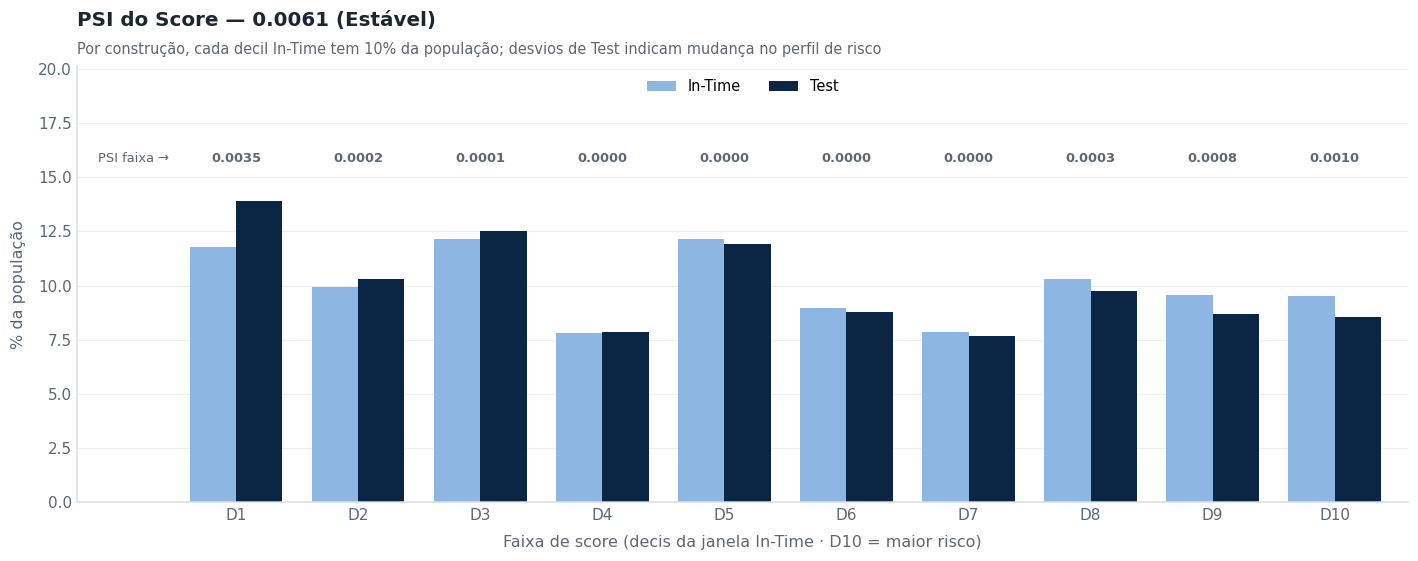

In [7]:
# ==============================================================================
# 4.2 PSI DO SCORE E CONCENTRAÇÃO NA CAUDA DE DECISÃO (D9–D10)
# ==============================================================================
df_psi_score, psi_score_total = calcular_psi_scores(df_val_scores['prob_cal'], df_pred['prob_cal'], bins=10)

share_d9_d10_val = float(df_psi_score.tail(2)['InTime_%'].sum() * 100)
share_d9_d10_test = float(df_psi_score.tail(2)['OOT_%'].sum() * 100)
print(f"Concentração nos 2 decis de maior risco (D9+D10): Validação = {share_d9_d10_val:.2f}% | Test = {share_d9_d10_test:.2f}%")

plot_psi_score_faixas(
    df_psi_score, psi_score_total, rotulo_atual='Test',
    filepath=DIR_FIG / '05_02_test_psi_score.png',
)

## 5.0 Monitoramento Temporal de Acionamento (Evolução Semanal)

Acompanhamos a evolução semanal da **taxa de bloqueio (`pred_fraude = 1`)** e do **score calibrado médio (`prob_cal`)** ao longo de todo o horizonte do `Test`, contrastando-os com a linha de referência da janela **Out-of-Time (OOT)**. Isso permite distinguir estabilidade normal de operação de picos sazonais de volume (a base não informa datas reais, então qualquer associação com fim de ano/Black Friday é apenas hipótese).

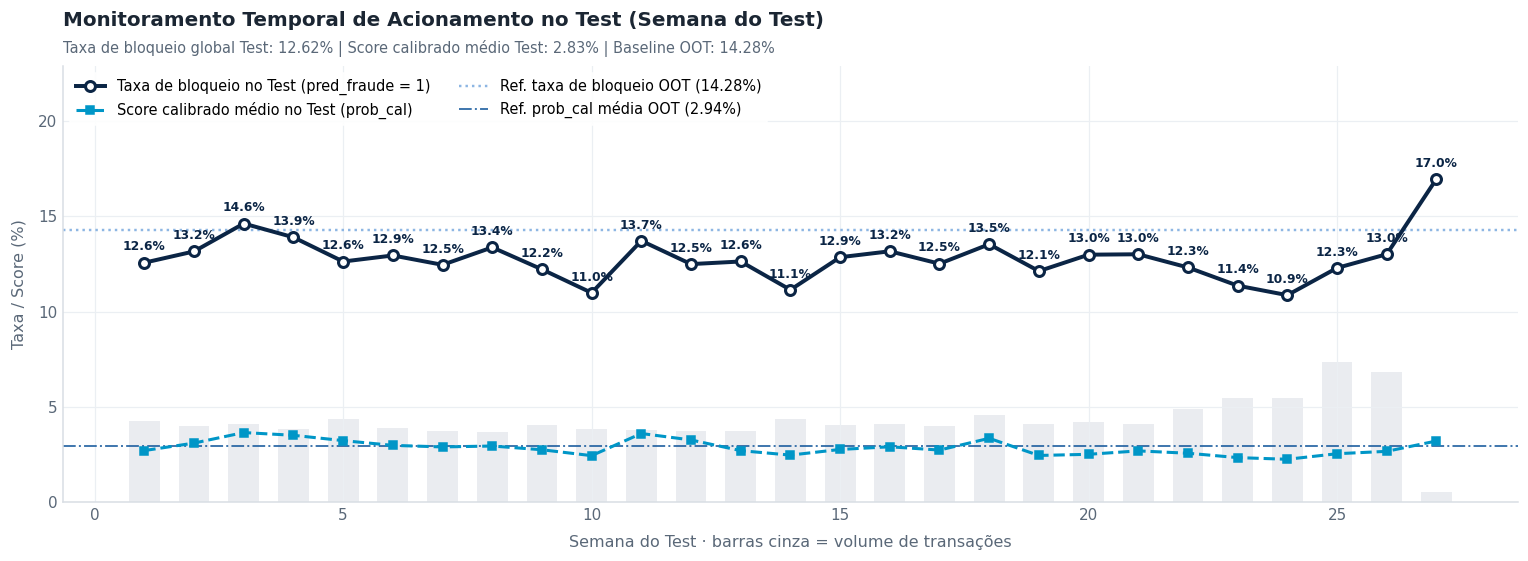

In [8]:
# ==============================================================================
# 5.1 EVOLUÇÃO SEMANAL DA TAXA DE BLOQUEIO E DO SCORE CALIBRADO VS. BASELINE OOT
# ==============================================================================
dt_ini_test = float(df_pred['TransactionDT'].min())
df_pred_t = adicionar_bloco_temporal(df_pred, dt_inicio=dt_ini_test, dias_por_bloco=7, nome_coluna='semana_test')
df_pred_t['semana_test'] = df_pred_t['semana_test'] + 1

df_semanal = resumir_predicoes_test(df_pred_t, 'semana_test')
# Filtra eventual última semana residual (< 1.000 transações) apenas para evitar distorção visual na borda
df_semanal_plot = df_semanal[df_semanal['Transacoes'] >= 1000].copy()

taxa_bloq_oot = float(df_oot_scores['bloquear'].mean() * 100)
prob_cal_oot = float(df_oot_scores['prob_cal'].mean() * 100)

plot_evolucao_predicoes_test(
    df_semanal_plot,
    col_bloco='semana_test',
    rotulo_bloco='Semana do Test',
    taxa_ref_oot=taxa_bloq_oot,
    prob_ref_oot=prob_cal_oot,
    filepath=DIR_FIG / '05_03_test_evolucao_semanal.png',
)

## 6.0 Exportação das Submissões e Síntese Executiva

Com o diagnóstico de estabilidade concluído, exportamos os dois arquivos finais em `data/submissions/` e consolidamos os indicadores de monitoramento em `reports/metrics/test_resumo_escoragem.json`:
1. **`submission_kaggle.csv`**: formato oficial da competição (`TransactionID,isFraud` com `isFraud = prob_cal` em 8 casas decimais). *Obs.:* a regressão isotônica gera **patamares** (várias transações com exatamente a mesma probabilidade), o que cria empates no ROC-AUC independentemente do número de casas decimais; como a métrica do Kaggle depende só da ordem, `prob_raw` preservaria melhor o ranqueamento.
2. **`predicoes_test_binarias.csv`**: trilha de auditoria operacional contendo `TransactionID`, `TransactionDT`, `ProductCD`, `amt_usd`, `prob_raw`, `prob_cal`, `threshold_dinamico` e `pred_fraude` (`0/1`).

In [9]:
# ==============================================================================
# 6.1 EXPORTAÇÃO E VALIDAÇÃO ESTRITA DOS CSVs DE SUBMISSÃO
# ==============================================================================
arq_kaggle = DIR_SUB / 'submission_kaggle.csv'
arq_binario = DIR_SUB / 'predicoes_test_binarias.csv'

df_kaggle = pd.DataFrame({
    'TransactionID': df_pred['TransactionID'].astype('int64'),
    'isFraud': df_pred['prob_cal'].astype('float64'),
})

cols_auditoria = [
    'TransactionID', 'TransactionDT', 'ProductCD', 'amt_usd',
    'prob_raw', 'prob_cal', 'threshold_dinamico', 'pred_fraude',
]
df_binario = df_pred[cols_auditoria].copy()
df_binario['TransactionID'] = df_binario['TransactionID'].astype('int64')

df_kaggle.to_csv(arq_kaggle, index=False, float_format='%.8f')
df_binario.to_csv(arq_binario, index=False, float_format='%.6f')

# Validações automáticas de integridade pós-escrita
chk_kag = pd.read_csv(arq_kaggle)
chk_bin = pd.read_csv(arq_binario)
assert list(chk_kag.columns) == ['TransactionID', 'isFraud'], "Cabeçalho inválido na submissão Kaggle."
assert len(chk_kag) == len(df_pred) and len(chk_bin) == len(df_pred), "Divergência no nº de linhas exportadas."
assert chk_kag['TransactionID'].is_unique, "TransactionID duplicado na submissão Kaggle."
assert not chk_kag.isna().any().any() and not chk_bin['pred_fraude'].isna().any(), "NaNs detectados nos CSVs."
assert chk_kag['isFraud'].between(0.0, 1.0).all(), "Scores fora do intervalo [0, 1]."
assert set(chk_bin['pred_fraude'].unique()).issubset({0, 1}), "pred_fraude deve conter apenas 0 e 1."

if arq_sample_sub.exists():
    sample_sub = pd.read_csv(arq_sample_sub, usecols=['TransactionID'])
    assert (chk_kag['TransactionID'].values == sample_sub['TransactionID'].values).all(), (
        "TransactionID fora de ordem em relação a sample_submission.csv."
    )
    print("[OK] Paridade de TransactionID 100% validada contra sample_submission.csv.")

print(f"[OK] Kaggle CSV    : {arq_kaggle} ({arq_kaggle.stat().st_size / 1e6:.2f} MB)")
print(f"[OK] Binário CSV   : {arq_binario} ({arq_binario.stat().st_size / 1e6:.2f} MB)")
display(chk_kag.head())

[OK] Paridade de TransactionID 100% validada contra sample_submission.csv.
[OK] Kaggle CSV    : /content/data/submissions/submission_kaggle.csv (9.63 MB)
[OK] Binário CSV   : /content/data/submissions/predicoes_test_binarias.csv (33.14 MB)


,TransactionID,isFraud
0,3663549,0.007044
1,3663550,0.011460
2,3663551,0.003182
3,3663552,0.007836
4,3663553,0.006879


In [10]:
# ==============================================================================
# 6.2 SÍNTESE EXECUTIVA DE MONITORAMENTO E EXPORTAÇÃO JSON
# ==============================================================================
vol_total = float(df_pred['amt_usd'].sum())
vol_bloq = float(df_pred['amt_bloqueado_usd'].sum())

resumo_executivo = {
    'modelo': str(artefato.get('nome_modelo', 'LGBM_Otimizado')),
    'n_features_modelo': int(len(FEATURES)),
    'n_transacoes_test': int(len(df_pred)),
    'prob_cal_media_val_pct': round(float(df_val_scores['prob_cal'].mean() * 100), 4),
    'prob_cal_media_oot_pct': round(float(df_oot_scores['prob_cal'].mean() * 100), 4),
    'prob_cal_media_test_pct': round(float(df_pred['prob_cal'].mean() * 100), 4),
    'taxa_bloqueio_val_pct': round(float(df_val_scores['bloquear'].mean() * 100), 4),
    'taxa_bloqueio_oot_pct': round(float(df_oot_scores['bloquear'].mean() * 100), 4),
    'taxa_bloqueio_test_pct': round(float(df_pred['pred_fraude'].mean() * 100), 4),
    'n_bloqueios_test': int(df_pred['pred_fraude'].sum()),
    'gmv_total_test_usd': round(vol_total, 2),
    'gmv_retido_test_usd': round(vol_bloq, 2),
    'pct_gmv_retido_test': round(vol_bloq / max(vol_total, 1e-9) * 100, 4),
    'psi_score_val_vs_test': round(float(psi_score_total), 5),
    'share_d9_d10_test_pct': round(share_d9_d10_test, 4),
    'features_psi_estavel': int(cont_status.get('Estável', 0)),
    'features_psi_alerta': int(cont_status.get('Alerta', 0)),
    'features_psi_critico': int(cont_status.get('Crítico', 0)),
    'arquivo_kaggle': str(arq_kaggle.relative_to(PROJECT_ROOT)),
    'arquivo_binario': str(arq_binario.relative_to(PROJECT_ROOT)),
}

arq_json = DIR_MET / 'test_resumo_escoragem.json'
arq_json.write_text(json.dumps(resumo_executivo, indent=2, ensure_ascii=False), encoding='utf-8')

display(pd.DataFrame([resumo_executivo]).T.rename(columns={0: 'Valor'}))
print(f"\nResumo salvo em: {arq_json}")

,Valor
modelo,LGBM_Otimizado
n_features_modelo,30
n_transacoes_test,506691
prob_cal_media_val_pct,3.0902
prob_cal_media_oot_pct,2.9368
prob_cal_media_test_pct,2.8283
taxa_bloqueio_val_pct,14.0617
taxa_bloqueio_oot_pct,14.2802
taxa_bloqueio_test_pct,12.6213
n_bloqueios_test,63951



Resumo salvo em: /content/reports/metrics/test_resumo_escoragem.json
